# Activity: Understanding, Exploring, and Preparing Data (NYC Taxi Dataset)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set plotting visual theme
sns.set_theme(style="whitegrid")

# Part 1: The NYC Taxis Dataset

## 1. Understanding the Dataset

In [ ]:
df = sns.load_dataset("taxis")

display(df.head())

print("Shape of the data: ", df.shape)

print("\n--- Dataset Info ---")
display(df.info())

print("\n--- Numerical Statistics ---")
df.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


Shape of the data:  (6433, 14)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object 

None


--- Numerical Statistics ---


,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223616,2019-03-16 08:45:49.491217408,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


# 2. Initial Data Inspection and EDA

## 2.1 Univariate EDA: Numerical Variables

### A. Numerical Summary

In [ ]:
display(df[["distance", "fare", "tip", "passengers"]].describe())

,distance,fare,tip,passengers
count,6433.000000,6433.000000,6433.00000,6433.000000
mean,3.024617,13.091073,1.97922,1.539251
std,3.827867,11.551804,2.44856,1.203768
min,0.000000,1.000000,0.00000,0.000000
25%,0.980000,6.500000,0.00000,1.000000
50%,1.640000,9.500000,1.70000,1.000000
75%,3.210000,15.000000,2.80000,2.000000
max,36.700000,150.000000,33.20000,6.000000


### B. Distance Distribution

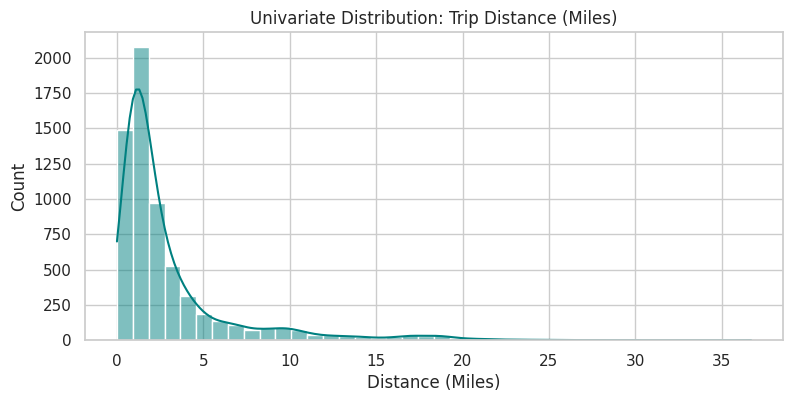

In [ ]:
plt.figure(figsize=(9,4))
sns.histplot(df["distance"], kde=True, color="teal", bins=40)
plt.title("Univariate Distribution: Trip Distance (Miles)")
plt.xlabel("Distance (Miles)")
plt.ylabel("Count")
plt.show()

The distribution of `distance` is right-skewed. Most of the trips are short.

## 2.2 Univariate EDA: Categorical Variables

In [ ]:
print("--- Taxi Color Distribution ---")
display(df["color"].value_counts())

print("\n--- Payment Method Distribution ---")
display(df["payment"].value_counts(dropna=False))

print("\n--- Pickup Borough Distribution ---")
display(df["pickup_borough"].value_counts(dropna=False))


--- Taxi Color Distribution ---


,count
color,
yellow,5451
green,982



--- Payment Method Distribution ---


,count
payment,
credit card,4577
cash,1812
NaN,44



--- Pickup Borough Distribution ---


,count
pickup_borough,
Manhattan,5268
Queens,657
Brooklyn,383
Bronx,99
NaN,26


## 2.3 Bivariate EDA: Two Variables

### A. Distance vs. Fare (Numerical vs. Numerical)

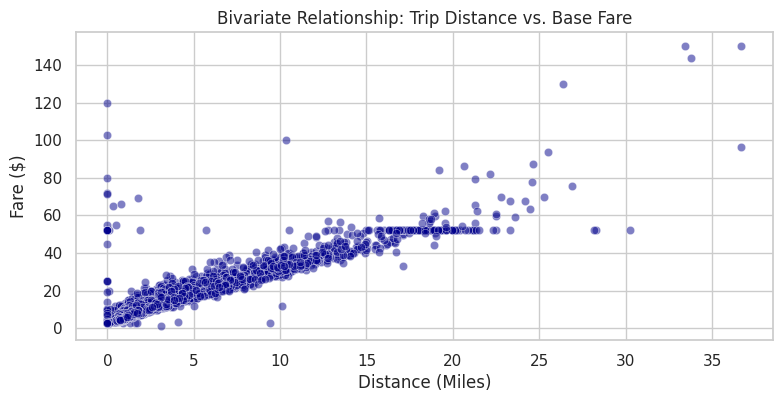

In [ ]:
plt.figure(figsize=(9,4))
sns.scatterplot(data=df, x="distance", y="fare", alpha=0.5, color="darkblue")
plt.title("Bivariate Relationship: Trip Distance vs. Base Fare")
plt.xlabel("Distance (Miles)")
plt.ylabel("Fare ($)")
plt.show()

### B. Average Tip by Payment Method (Categorical vs. Numerical)

/tmp/ipykernel_1163/1966923500.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="payment", y="tip", errorbar=None, palette='Set2')


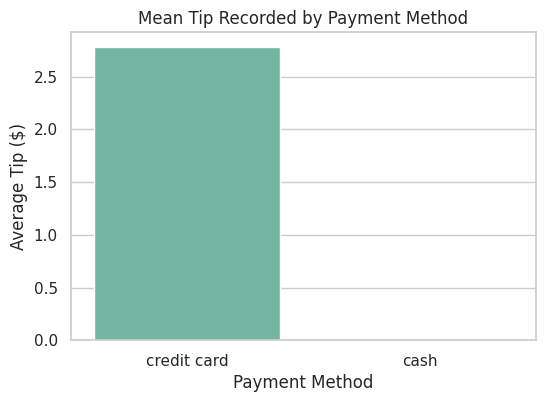

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(data=df, x="payment", y="tip", errorbar=None, palette='Set2')
plt.title("Mean Tip Recorded by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Tip ($)")
plt.show()

## 2.4 Bivariate EDA with a Third Dimension (hue)

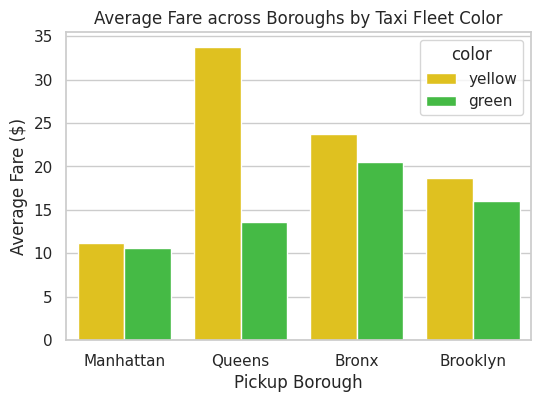

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(data=df, x="pickup_borough", y="fare", hue="color", errorbar=None, palette=["gold", "limegreen"])
plt.title('Average Fare across Boroughs by Taxi Fleet Color')
plt.xlabel('Pickup Borough')
plt.ylabel('Average Fare ($)')
plt.show()

## 2.5 Multivariate EDA: Correlation Matrix

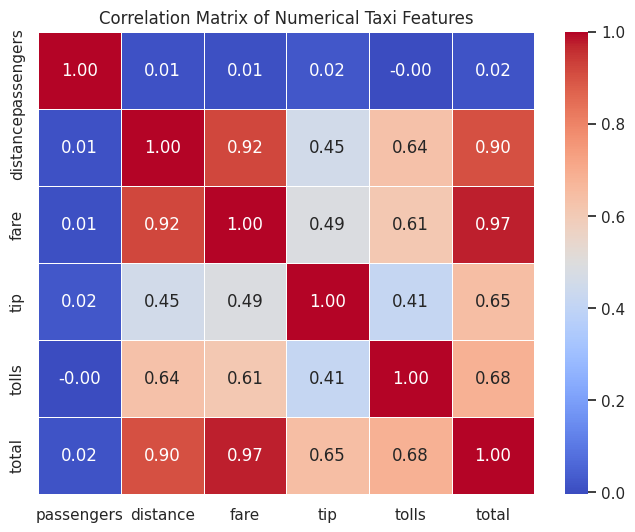

In [ ]:
# 1. Select numeric columns
numeric_taxis = df.select_dtypes(include='number')

# 2. Compute correlation matrix
corr_matrix = numeric_taxis.corr()

# 3. Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Taxi Features')
plt.show()

- (distance, fare), (distance, total), (fare, total).
- `passengers` do not correlate strongly with `fare` or `distance`.
- Generally, distance is one of the reasons for higher fare, cause fares are based on the distance mesaurement.

## 2.6 Investigating Potential Outliers

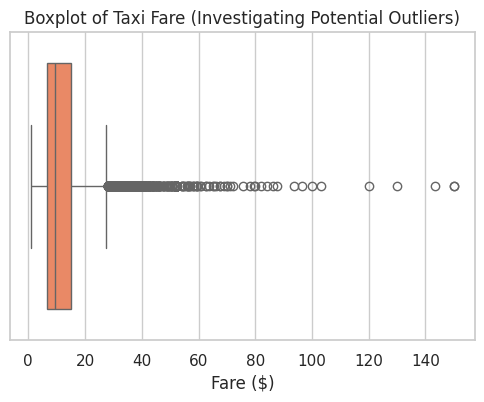

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["fare"], color="coral")
plt.title("Boxplot of Taxi Fare (Investigating Potential Outliers)")
plt.xlabel("Fare ($)")

plt.show()

## 3. Identify Data-Quality Problems

In [ ]:
# 1. Missing values
print("--- Missing Values ---")
display(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Duplicate rows
print(f"\nDuplicate Rows: {df.duplicated().sum()}")

# 3. Check minimum values for potential invalid entries (e.g. 0 distance or 0 passengers)
print("\n--- Minimum Values Check ---")
display(df[['distance', 'fare', 'passengers']].min())

--- Missing Values ---


,0
payment,44
pickup_zone,26
dropoff_zone,45
pickup_borough,26
dropoff_borough,45



Duplicate Rows: 0

--- Minimum Values Check ---


,0
distance,0.0
fare,1.0
passengers,0.0


# 4. Data Cleaning

## 4.1 Handling Missing Values

In [ ]:
# 1. Impute missing 'payment' with mode
mode_payment = df["payment"].mode()[0]
df["payment"] = df["payment"].fillna(mode_payment)

# 2. Drop rows with missing borough values
df.dropna(subset=["pickup_borough", "dropoff_borough"], inplace=True)

# 3. Verify missing counts
print("Missing values after data cleaning")
display(df[["payment", "pickup_borough", "dropoff_borough"]].isnull().sum())

Missing values after data cleaning


,0
payment,0
pickup_borough,0
dropoff_borough,0


## 4.2 Handling Zero-Distance / Zero-Passenger Anomalies

In [ ]:
# Filter and inspect zero-distance trips with fare
zero_dist_count = (df["distance"] == 0).sum()
print(f"Number of zero-distance trips: {zero_dist_count}")

# For this demo, remove zero-distance anomalies to maintain physical relationship integrity
df = df[df["distance"] > 0].copy()

Number of zero-distance trips: 36


# 5. EDA Again: Validate the Cleaning

## 5.1 Check the Payment Distribution Again

/tmp/ipykernel_1163/505375105.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='payment', palette='Set2')


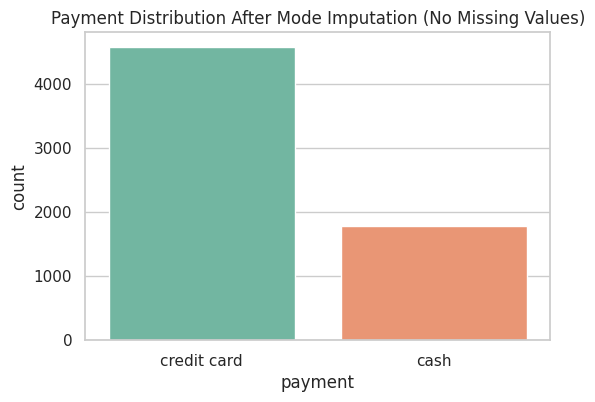

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='payment', palette='Set2')
plt.title('Payment Distribution After Mode Imputation (No Missing Values)')
plt.show()

## 5.2 Check Distance vs. Fare Again

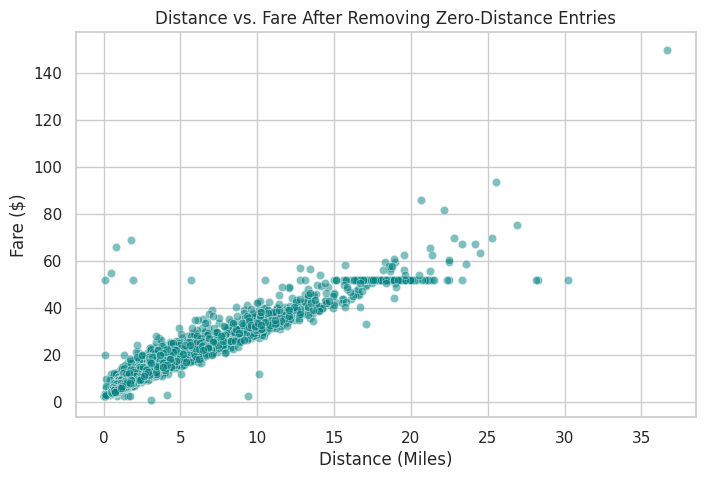

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='distance', y='fare', alpha=0.5, color='teal')
plt.title('Distance vs. Fare After Removing Zero-Distance Entries')
plt.xlabel('Distance (Miles)')
plt.ylabel('Fare ($)')
plt.show()

# 6. Feature Engineering & Preprocessing
Feature engineering transforms raw columns into more informative numerical inputs for machine learning.

## 6.1 Creating New Features: Tip Percentage and Trip Duration

In [ ]:
# 1. Calculate tip percentage
df['tip_pct'] = (df['tip'] / df['fare']) * 100

# 2. Convert timestamps to datetime and calculate duration in minutes
df['pickup'] = pd.to_datetime(df['pickup'])
df['dropoff'] = pd.to_datetime(df['dropoff'])

df['duration_min'] = (df['dropoff'] - df['pickup']).dt.total_seconds() / 60.0

# Preview new engineered features
display(df[['distance', 'fare', 'tip', 'tip_pct', 'duration_min']].head())

,distance,fare,tip,tip_pct,duration_min
0,1.60,7.0,2.15,30.714286,6.250000
1,0.79,5.0,0.00,0.000000,7.083333
2,1.37,7.5,2.36,31.466667,7.400000
3,7.70,27.0,6.15,22.777778,25.866667
4,2.16,9.0,1.10,12.222222,9.533333


## 6.2 Encoding Categorical Variables (One-Hot Encoding)

Machine learning models require numeric inputs.

- We apply One-Hot Encoding to nominal features (color, payment, pickup_borough).
- We set drop_first=True to avoid the dummy variable trap (multicollinearity).
- We set dtype=int to ensure columns are encoded as 0 and 1 instead of True and False.

In [ ]:
# One-hot encode categorical predictors
df_taxis_encoded = pd.get_dummies(df, columns=['color', 'payment', 'pickup_borough'], drop_first=True, dtype=int)

# Preview encoded columns
display(df_taxis_encoded.head())

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,pickup_zone,dropoff_zone,dropoff_borough,tip_pct,duration_min,color_yellow,payment_credit card,pickup_borough_Brooklyn,pickup_borough_Manhattan,pickup_borough_Queens
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,Lenox Hill West,UN/Turtle Bay South,Manhattan,30.714286,6.250000,1,1,0,1,0
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,Upper West Side South,Upper West Side South,Manhattan,0.000000,7.083333,1,0,0,1,0
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,Alphabet City,West Village,Manhattan,31.466667,7.400000,1,1,0,1,0
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,Hudson Sq,Yorkville West,Manhattan,22.777778,25.866667,1,1,0,1,0
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,Midtown East,Yorkville West,Manhattan,12.222222,9.533333,1,1,0,1,0


# 7. Dropping Redundant Columns & Final Preparation

In [ ]:
# Define redundant/high-cardinality columns
cols_to_drop = ['pickup', 'dropoff', 'pickup_zone', 'dropoff_zone', 'dropoff_borough']

# Create final prepared DataFrame
df_prepared = df_taxis_encoded.drop(columns=cols_to_drop)

print("--- Final Prepared Dataset ---")
df_prepared.info()

--- Final Prepared Dataset ---
<class 'pandas.core.frame.DataFrame'>
Index: 6347 entries, 0 to 6432
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   passengers                6347 non-null   int64  
 1   distance                  6347 non-null   float64
 2   fare                      6347 non-null   float64
 3   tip                       6347 non-null   float64
 4   tolls                     6347 non-null   float64
 5   total                     6347 non-null   float64
 6   tip_pct                   6347 non-null   float64
 7   duration_min              6347 non-null   float64
 8   color_yellow              6347 non-null   int64  
 9   payment_credit card       6347 non-null   int64  
 10  pickup_borough_Brooklyn   6347 non-null   int64  
 11  pickup_borough_Manhattan  6347 non-null   int64  
 12  pickup_borough_Queens     6347 non-null   int64  
dtypes: float64(7), int64(6)
memory usage:

# 8. Exporting the Data

In [ ]:
# Export clean dataset to CSV
df_prepared.to_csv("taxis_prepared.csv", index=False)
print("Successfully exported 'taxis_prepared.csv'")

Successfully exported 'taxis_prepared.csv'


# 9. Understanding and Inspecting Iris

In [4]:
# Load Iris dataset
df_iris = sns.load_dataset("iris")

# Display structure and missing counts
display(df_iris.head())
print("Shape:", df_iris.shape)
print("\nMissing values in Iris:")
display(df_iris.isnull().sum())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Shape: (150, 5)

Missing values in Iris:


,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


# 10. Iris: Multivariate EDA with Pairplot

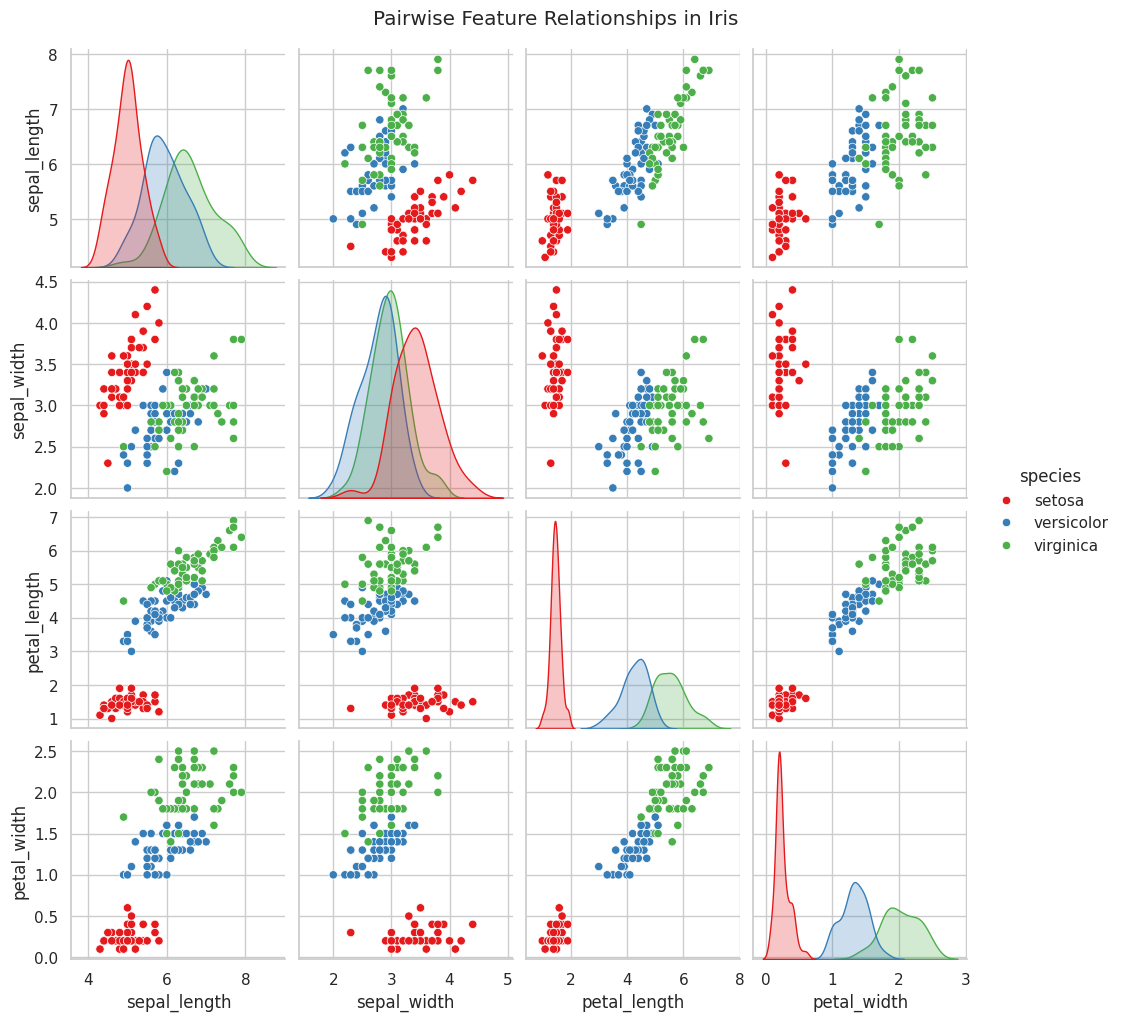

In [6]:
sns.pairplot(df_iris, hue="species", palette="Set1")
plt.suptitle("Pairwise Feature Relationships in Iris", y=1.02)
plt.show()